# Practical 7 — Artificial Neural Network (Multi-Layer Perceptron)

**Aim:** Train a feed-forward neural network to classify breast tumours and evaluate it with train/test split and k-fold CV
(Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1, AUC).

**Dataset:** Breast Cancer Wisconsin (Diagnostic) – UCI, bundled with scikit-learn.

**Idea:** An MLP stacks layers of neurons. Each neuron computes `activation(w·inputs + b)`.
* **Forward pass:** input → hidden layer 1 (ReLU) → hidden layer 2 (ReLU) → output neuron (sigmoid = P(malignant)).
* **Loss:** log-loss between the output and the true label.
* **Backpropagation:** the chain rule gives the gradient of the loss w.r.t. every weight.
* **Optimiser (Adam):** updates the weights with those gradients; one pass over the data = one *epoch*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 4)

## Evaluation helpers (shared by all classification practicals)
The syllabus asks us to report **Accuracy, TP, TN, FP, FN, Error, Recall, Specificity, F1-score and AUC**.
* `classification_metrics` – builds the confusion matrix `[[TN, FP], [FN, TP]]` and derives every metric from it
  (formulas are in the docstring).
* `kfold_evaluate` – manual **stratified k-fold cross-validation**: for every fold it clones the model, trains on
  k-1 folds, tests on the held-out fold and records all metrics, so you can see each intermediate result.

In [2]:
from sklearn.base import clone
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.model_selection import StratifiedKFold


def classification_metrics(y_true, y_pred, y_score=None):
    """Return all metrics required by the syllabus for a BINARY problem (positive class = 1).

    Accuracy    = (TP+TN)/(TP+TN+FP+FN)      Error       = 1 - Accuracy
    Recall      = TP/(TP+FN)  (sensitivity)  Specificity = TN/(TN+FP)
    Precision   = TP/(TP+FP)                 F1          = 2*P*R/(P+R)
    AUC         = area under the ROC curve (needs a continuous score, not the hard label)
    """
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    auc = roc_auc_score(y_true, y_score) if y_score is not None else np.nan
    return pd.Series({"TP": tp, "TN": tn, "FP": fp, "FN": fn, "Accuracy": accuracy,
                      "Error": 1 - accuracy, "Recall": recall, "Specificity": specificity,
                      "Precision": precision, "F1": f1, "AUC": auc})


def get_score(model, X):
    """Continuous score used for AUC: P(class=1) if available, otherwise the SVM-style decision value."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def kfold_evaluate(model, X, y, k=5, seed=42):
    """Stratified k-fold CV. Returns (per-fold table, mean/std summary)."""
    X, y = np.asarray(X), np.asarray(y)
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    rows = []
    for fold, (tr, te) in enumerate(skf.split(X, y), start=1):
        m = clone(model).fit(X[tr], y[tr])                 # fresh, untrained copy each fold
        r = classification_metrics(y[te], m.predict(X[te]), get_score(m, X[te]))
        r.name = f"Fold {fold}"
        rows.append(r)
        print(f"Fold {fold}: train={len(tr)}, test={len(te)}, accuracy={r['Accuracy']:.4f}, AUC={r['AUC']:.4f}")
    folds = pd.DataFrame(rows)
    return folds, pd.DataFrame({"mean": folds.mean(), "std": folds.std()})


def plot_cm_roc(model, X_test, y_test, title=""):
    """Confusion matrix + ROC curve side by side."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax[0], cmap="Blues",
                                          display_labels=["Benign (0)", "Malignant (1)"])
    ax[0].set_title(f"Confusion matrix {title}")
    fpr, tpr, _ = roc_curve(y_test, get_score(model, X_test))
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc_score(y_test, get_score(model, X_test)):.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", label="Chance")
    ax[1].set(xlabel="False Positive Rate (1 - Specificity)", ylabel="True Positive Rate (Recall)",
              title=f"ROC curve {title}")
    ax[1].legend(); plt.tight_layout(); plt.show()

## Step 1 — Load and inspect the data

In [3]:
data = load_breast_cancer(as_frame=True)
X_df = data.data                                  # 30 numeric features
y_s = (data.target == 0).astype(int)              # flip so that 1 = MALIGNANT (the "positive" class), 0 = benign
df = X_df.assign(target=y_s)

print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("\nClass balance (1 = malignant):")
print(y_s.value_counts().rename({0: "benign", 1: "malignant"}))
df.head()

Shape: (569, 31)
Missing values: 0

Class balance (1 = malignant):
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,1


## Step 2 — Split and scale
Neural networks are very sensitive to feature scale, so standardisation is essential (mean 0, std 1; learned from the training set only).

In [4]:
X, y = X_df.values, y_s.values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", Xs_train.shape, "Test:", Xs_test.shape)

Train: (455, 30) Test: (114, 30)


## Step 3 — Build and train the network
Architecture: **30 inputs → 16 ReLU → 8 ReLU → 1 sigmoid output**.
* `hidden_layer_sizes=(16, 8)` – two hidden layers
* `activation="relu"` – max(0, z)
* `solver="adam"` – adaptive gradient optimiser; `max_iter` = number of epochs
* `early_stopping` is off so we can plot the whole loss curve.

Epochs run          : 348
Final training loss : 0.01261
Layers (in→out)     : [30, 16, 8, 1]
  layer 0: weight matrix (30, 16), bias vector (16,)
  layer 1: weight matrix (16, 8), bias vector (8,)
  layer 2: weight matrix (8, 1), bias vector (1,)
Total trainable parameters: 641


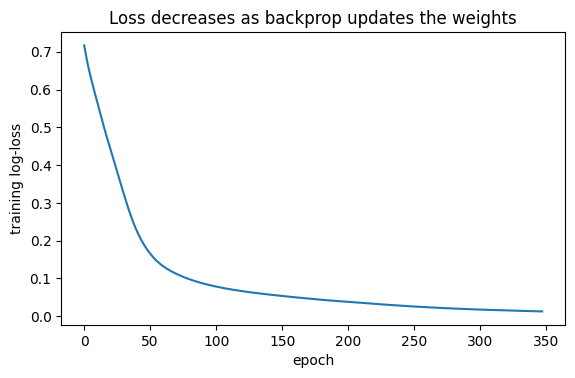

In [5]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                    max_iter=500, random_state=42)
mlp.fit(Xs_train, y_train)

print("Epochs run          :", mlp.n_iter_)
print("Final training loss :", round(mlp.loss_, 5))
print("Layers (in→out)     :", [mlp.n_features_in_] + list(mlp.hidden_layer_sizes) + [mlp.n_outputs_])
for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_)):
    print(f"  layer {i}: weight matrix {W.shape}, bias vector {b.shape}")
print("Total trainable parameters:", sum(W.size + b.size for W, b in zip(mlp.coefs_, mlp.intercepts_)))

plt.figure(figsize=(6.5, 3.8))
plt.plot(mlp.loss_curve_); plt.xlabel("epoch"); plt.ylabel("training log-loss"); plt.title("Loss decreases as backprop updates the weights")
plt.show()

## Step 4 — The forward pass by hand
This is exactly what `predict_proba()` does for one sample. We use the weights the network learned.
1. h₁ = ReLU(x·W₀ + b₀)  → 16 values
2. h₂ = ReLU(h₁·W₁ + b₁) → 8 values
3. z = h₂·W₂ + b₂ → 1 value, then p = σ(z)

In [6]:
relu = lambda a: np.maximum(0, a)
sigmoid = lambda a: 1 / (1 + np.exp(-a))

x0 = Xs_test[0]
a1 = x0 @ mlp.coefs_[0] + mlp.intercepts_[0]; h1 = relu(a1)
a2 = h1 @ mlp.coefs_[1] + mlp.intercepts_[1]; h2 = relu(a2)
z = h2 @ mlp.coefs_[2] + mlp.intercepts_[2]; p = sigmoid(z)[0]

print("Input x (first 5 of 30)   :", x0[:5].round(3))
print("Step 4.1 pre-activation a1 (first 5):", a1[:5].round(3))
print("         after ReLU h1     (first 5):", h1[:5].round(3), f"| {int((h1 == 0).sum())} of 16 neurons inactive")
print("Step 4.2 after layer 2, h2 (8 values):", h2.round(3))
print(f"Step 4.3 output z = {z[0]:.4f}  →  p = σ(z) = {p:.3e}")
print(f"\nManual  P(malignant): {p:.6e}")
print(f"sklearn P(malignant): {mlp.predict_proba(x0.reshape(1, -1))[0, 1]:.6e}")
print("Match:", np.isclose(p, mlp.predict_proba(x0.reshape(1, -1))[0, 1]))
print("True label:", y_test[0], "| Predicted:", int(p >= 0.5))

Input x (first 5 of 30)   : [-0.771 -2.006 -0.765 -0.712 -0.158]
Step 4.1 pre-activation a1 (first 5): [ 1.494 -2.477 -2.375  0.72   2.812]
         after ReLU h1     (first 5): [1.494 0.    0.    0.72  2.812] | 7 of 16 neurons inactive
Step 4.2 after layer 2, h2 (8 values): [0.    2.844 5.394 6.08  0.    2.335 2.447 2.395]
Step 4.3 output z = -14.0721  →  p = σ(z) = 7.737e-07

Manual  P(malignant): 7.737151e-07
sklearn P(malignant): 7.737151e-07
Match: True
True label: 0 | Predicted: 0


## Step 5 — One backpropagation step in numbers (output layer)
For a sigmoid output with log-loss, the error signal at the output is simply **δ = p − y**.
The gradient for the last weight matrix is h₂ᵀ·δ. Adam then moves each weight a small step against its gradient.
Below: the gradient for the last layer for the same sample.

In [7]:
delta = p - y_test[0]
grad_W2 = np.outer(h2, delta)
print(f"output error δ = p − y = {p:.2e} − {y_test[0]} = {delta:.2e}  (tiny: the network is already confident and right, so almost no update)")
print("gradient ∂L/∂W₂ (8 values):", grad_W2.ravel().round(4))
print("→ each of the 8 output weights is nudged by −learning_rate × gradient (scaled by Adam's moment estimates).")

output error δ = p − y = 7.74e-07 − 0 = 7.74e-07  (tiny: the network is already confident and right, so almost no update)
gradient ∂L/∂W₂ (8 values): [0. 0. 0. 0. 0. 0. 0. 0.]
→ each of the 8 output weights is nudged by −learning_rate × gradient (scaled by Adam's moment estimates).


## Step 6 — Evaluation on the hold-out test set

,Train,Test
TP,168.0000,41.0000
TN,285.0000,72.0000
FP,0.0000,0.0000
FN,2.0000,1.0000
Accuracy,0.9956,0.9912
Error,0.0044,0.0088
Recall,0.9882,0.9762
Specificity,1.0000,1.0000
Precision,1.0000,1.0000
F1,0.9941,0.9880


              precision    recall  f1-score   support

      benign       0.99      1.00      0.99        72
   malignant       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



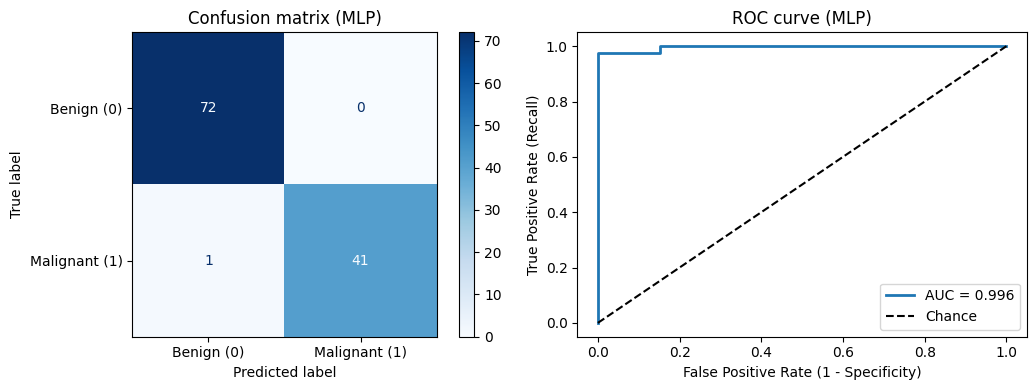

In [8]:
y_pred = mlp.predict(Xs_test)
test_m = classification_metrics(y_test, y_pred, mlp.predict_proba(Xs_test)[:, 1])
train_m = classification_metrics(y_train, mlp.predict(Xs_train), mlp.predict_proba(Xs_train)[:, 1])
display(pd.DataFrame({"Train": train_m, "Test": test_m}).round(4))
print(classification_report(y_test, y_pred, target_names=["benign", "malignant"]))
plot_cm_roc(mlp, Xs_test, y_test, title="(MLP)")

## Step 7 — Effect of network size
Compare a few architectures on the test set to see under-/over-capacity (each is trained from scratch).

In [9]:
rows = []
for hl in [(2,), (8,), (16, 8), (64, 32), (128, 64, 32)]:
    m = MLPClassifier(hidden_layer_sizes=hl, max_iter=1000, random_state=42).fit(Xs_train, y_train)
    r = classification_metrics(y_test, m.predict(Xs_test), m.predict_proba(Xs_test)[:, 1])
    rows.append({"hidden layers": str(hl), "epochs": m.n_iter_, "train_acc": m.score(Xs_train, y_train),
                 "test_acc": r["Accuracy"], "test_recall": r["Recall"], "test_AUC": r["AUC"]})
display(pd.DataFrame(rows).set_index("hidden layers").round(4))

,epochs,train_acc,test_acc,test_recall,test_AUC
hidden layers,,,,,
"(2,)",464,0.9846,0.9912,0.9762,0.9983
"(8,)",478,0.9912,0.9825,0.9524,0.9954
"(16, 8)",348,0.9956,0.9912,0.9762,0.9964
"(64, 32)",186,1.0000,0.9649,0.9048,0.9927
"(128, 64, 32)",96,1.0000,0.9737,0.9286,0.9950


## Step 8 — k-fold cross-validation (k = 5)
The scaler is part of the pipeline so it is learned on each training fold only.

In [10]:
pipe = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=42))
folds, summary = kfold_evaluate(pipe, X, y, k=5)
print()
display(folds.round(4)); display(summary.round(4))

Fold 1: train=455, test=114, accuracy=0.9737, AUC=0.9990
Fold 2: train=455, test=114, accuracy=0.9474, AUC=0.9941


Fold 3: train=455, test=114, accuracy=0.9561, AUC=0.9762
Fold 4: train=455, test=114, accuracy=0.9737, AUC=0.9993


Fold 5: train=456, test=113, accuracy=0.9912, AUC=0.9990



,TP,TN,FP,FN,Accuracy,Error,Recall,Specificity,Precision,F1,AUC
Fold 1,43.0,68.0,3.0,0.0,0.9737,0.0263,1.0000,0.9577,0.9348,0.9663,0.9990
Fold 2,37.0,71.0,0.0,6.0,0.9474,0.0526,0.8605,1.0000,1.0000,0.9250,0.9941
Fold 3,37.0,72.0,0.0,5.0,0.9561,0.0439,0.8810,1.0000,1.0000,0.9367,0.9762
Fold 4,42.0,69.0,3.0,0.0,0.9737,0.0263,1.0000,0.9583,0.9333,0.9655,0.9993
Fold 5,41.0,71.0,0.0,1.0,0.9912,0.0088,0.9762,1.0000,1.0000,0.9880,0.9990


,mean,std
TP,40.0000,2.8284
TN,70.2000,1.6432
FP,1.2000,1.6432
FN,2.4000,2.8810
Accuracy,0.9684,0.0171
Error,0.0316,0.0171
Recall,0.9435,0.0676
Specificity,0.9832,0.0230
Precision,0.9736,0.0361
F1,0.9563,0.0252


## Step 9 — Summary

In [11]:
display(pd.DataFrame({"Hold-out test": test_m, "5-fold CV mean": summary["mean"]}).round(4))

,Hold-out test,5-fold CV mean
TP,41.0000,40.0000
TN,72.0000,70.2000
FP,0.0000,1.2000
FN,1.0000,2.4000
Accuracy,0.9912,0.9684
Error,0.0088,0.0316
Recall,0.9762,0.9435
Specificity,1.0000,0.9832
Precision,1.0000,0.9736
F1,0.9880,0.9563


### Conclusion
* The network learns non-linear combinations of the 30 inputs; the falling loss curve shows backpropagation + Adam optimising the weights.
* The manual forward pass reproduces `predict_proba` exactly, so a prediction is just *matrix multiply → ReLU → matrix multiply → ReLU → matrix multiply → sigmoid*.
* Bigger networks reach 100 % training accuracy but do not improve test accuracy (they may even be slightly worse); on a small tabular dataset like this a small MLP is enough.
* MLP results depend on random initialisation – hence the fixed `random_state` and the value of cross-validation.